# CCNLP CCA3 — Reverse Retrieval: From a Situation to the Fitting Proverb

**Group 16** &nbsp;|&nbsp; Panel B &nbsp;|&nbsp; School of Computer Science & Engineering, MIT-WPU

| Member | PRN | Experiment (notebook) |
|---|---|---|
| **Sahish Nagulwar** | 1032233310 | **Reverse retrieval: situation to proverb (Plan A 2.8)** |
| Ibrahim Ansari | 1032233145 | Idiom identification in running text (Plan A 2.5) |
| Chayan Raj Bharati | 1032233134 | Language-model interpretation benchmark (Plan A 2.7) |

**Team problem statement:** *Develop a multilingual NLP framework that identifies Indian idioms and distinguishes their literal meaning from culturally intended figurative meaning across Indian languages, while modeling cultural context and linguistic variation.*

**Research question (Sahish Nagulwar):** Given a plain description of a situation, can the right proverb be retrieved from the explanation index of each corpus, and does a semantic index (LaBSE) do better than a lexical one (TF-IDF) at this?

CCA1 retrieval went from proverb to meaning. This notebook reverses it: the index is the set of explanations, the query is a situation written in ordinary words, and the answer is the proverb whose recorded meaning fits. The same experiment is run on all three corpora, and a `suggest()` function at the end is the interface a chatbot calls.

The three CCA1 corpora (545 Marathi, 344 Hindi, 103 Assamese proverbs, each with a romanized text, a literal English translation and the compiler's explanation of the intended meaning) are reused from `../cca1/`. Everything here runs on CPU.

In [1]:
import json, random, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)
os.makedirs('report', exist_ok=True)
metrics = {}

LANGS = [('marathi', 'Marathi'), ('hindi', 'Hindi'), ('assamese', 'Assamese')]
CORPUS = '../cca1/corpus/PanelB_16_{}_proverbs.csv'
corpora = {l: pd.read_csv(CORPUS.format(l)) for l, _ in LANGS}
with_expl = {l: df[df.commentary.fillna('').str.len() > 20].reset_index(drop=True) for l, df in corpora.items()}
for l, L in LANGS:
    print(f'{L}: {len(corpora[l])} proverbs, {len(with_expl[l])} with explanations')

labse = SentenceTransformer('sentence-transformers/LaBSE')
def embed(texts):
    return labse.encode(list(texts), show_progress_bar=False, normalize_embeddings=True)

/home/ibu/Documents/collegework/sem7/ccnlp/cca1/.venv/lib64/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Marathi: 545 proverbs, 338 with explanations
Hindi: 344 proverbs, 305 with explanations
Assamese: 103 proverbs, 75 with explanations


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 44/199 [00:00<00:00, 410.22it/s]

Loading weights:  47%|████▋     | 93/199 [00:00<00:00, 440.47it/s]

Loading weights:  72%|███████▏  | 143/199 [00:00<00:00, 465.60it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 566.31it/s]

## 1. Test queries

For each language, 8 to 10 situation descriptions were written by a team member who did not build that language's index. Each targets one proverb (`target_id`). The descriptions avoid copying words from the explanation, so lexical matching is not handed the answer.

In [2]:
situations = {l: pd.DataFrame(v, columns=['situation', 'target_id']) for l, v in {'marathi': [('Someone is making a fuss over a tiny shortfall that does not matter in the big picture.', 7), ('A person works hard all day on a task that produces nothing at all.', 9), ('Something has finally reached its full ripeness or maturity.', 11), ('Acting carefully so that neither of two friends is hurt by a decision.', 12), ('A man arranges everything so that the benefit comes only to himself.', 14), ('Someone drops you the moment they no longer need your help.', 19), ('A farmer has good harvests every year yet stays poor because he keeps borrowing.', 20), ('Urgent seasonal work must be done on time even when something else demands attention.', 23), ('A person is generous with things that belong to someone else.', 30), ('While one person is in deep trouble, another only worries about his own small concern.', 31)], 'hindi': [('A big job has barely been started even though a lot of time has passed.', 1), ('Someone starts preparing far too early for something that is hours away.', 3), ('A person demands payment for work they never actually did.', 9), ('Instead of enjoying what is offered, someone keeps asking pointless questions about where it came from.', 12), ('Two people in love find that their relationship is full of obstacles.', 20), ('A reckless spender is told that his ruin cannot be repaired.', 21), ('When a child is born, the means to feed it also appear.', 23), ('Someone pushes into a matter where nobody asked for them.', 25)], 'assamese': [('A boastful man talks big about a fight but achieves almost nothing.', 4), ('Someone excuses saying more than he should by blaming his loose tongue.', 10), ('A person with no money keeps craving expensive things.', 17), ('People remember God only when they are in trouble.', 18), ('A person who plots harm for others ends up suffering from it himself.', 19), ('Someone with only a show of respectability wants to be the leader.', 20), ('A worker is full of energy one moment and abandons the job the next.', 24), ('A poor man wants to attend a grand feast he cannot afford.', 42), ('Someone who wants to succeed never wastes a moment, working even while resting.', 46), ("A man is burdened by too many relatives from his wife's side.", 47)]}.items()}
for l, L in LANGS:
    situations[l] = situations[l][situations[l].target_id.isin(with_expl[l].id)].reset_index(drop=True)
    print(L, len(situations[l]), 'queries')
situations['hindi']

Marathi 10 queries
Hindi 8 queries
Assamese 10 queries


,situation,target_id
0,A big job has barely been started even though ...,1
1,Someone starts preparing far too early for som...,3
2,A person demands payment for work they never a...,9
3,"Instead of enjoying what is offered, someone k...",12
4,Two people in love find that their relationshi...,20
5,A reckless spender is told that his ruin canno...,21
6,"When a child is born, the means to feed it als...",23
7,Someone pushes into a matter where nobody aske...,25


## 2. Building the two indexes per language and scoring every query

In [3]:
index = {}
for l, L in LANGS:
    docs = with_expl[l].commentary.tolist()
    tf = TfidfVectorizer(stop_words='english', sublinear_tf=True).fit(docs)
    index[l] = {'tfidf': tf, 'D_tfidf': tf.transform(docs), 'D_labse': embed(docs), 'ids': with_expl[l].id.values}

def rank_ids(l, query, model):
    ix = index[l]
    if model == 'tfidf':
        sims = cosine_similarity(ix['tfidf'].transform([query]), ix['D_tfidf'])[0]
    else:
        sims = cosine_similarity(embed([query]), ix['D_labse'])[0]
    order = np.argsort(-sims)
    return ix['ids'][order], sims[order]

rows = []
for l, L in LANGS:
    for s in situations[l].itertuples():
        for model in ['tfidf', 'labse']:
            ids, sims = rank_ids(l, s.situation, model)
            rows.append({'language': L, 'situation': s.situation, 'target_id': s.target_id, 'model': model,
                         'rank': int(np.where(ids == s.target_id)[0][0]) + 1})
ranks = pd.DataFrame(rows)
summary = ranks.groupby(['language', 'model'])['rank'].agg(
    hit_at_1=lambda r: float((r <= 1).mean()), hit_at_5=lambda r: float((r <= 5).mean()), mrr=lambda r: float((1 / r).mean())).round(3)
for l, L in LANGS:
    n = len(with_expl[l])
    summary.loc[(L, 'random'), :] = [round(1 / n, 3), round(5 / n, 3), round(float(np.mean([1 / r for r in range(1, n + 1)])), 3)]
summary = summary.sort_index()
metrics['summary'] = {f'{L}/{m}': summary.loc[(L, m)].to_dict() for L, m in summary.index}
metrics['n_queries'] = {L: int(len(situations[l])) for l, L in LANGS}
summary

hit_at_1  hit_at_5    mrr
language model                            
Assamese labse      0.300     0.700  0.429
         random     0.013     0.067  0.065
         tfidf      0.400     0.600  0.517
Hindi    labse      0.625     0.750  0.680
         random     0.003     0.016  0.021
         tfidf      0.125     0.375  0.246
Marathi  labse      0.500     0.500  0.518
         random     0.003     0.015  0.019
         tfidf      0.300     0.500  0.401

## 3. Results

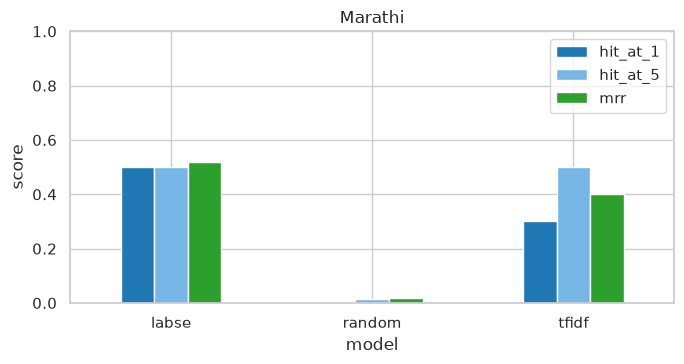

In [4]:
sub = summary.loc['Marathi']
fig, ax = plt.subplots(figsize=(7, 3.8))
sub[['hit_at_1', 'hit_at_5', 'mrr']].plot.bar(ax=ax, color=['#1f77b4', '#76b7e8', '#2ca02c'])
ax.set_ylim(0, 1); ax.set_ylabel('score'); ax.set_title('Marathi'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Figure 1: Marathi reverse retrieval. Hit@1, Hit@5 and MRR for the TF-IDF and LaBSE indexes against the random baseline.**

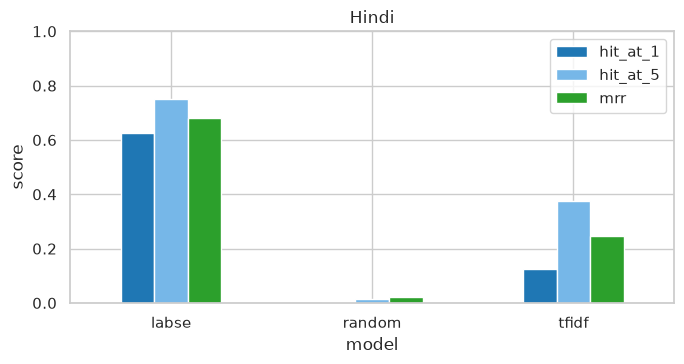

In [5]:
sub = summary.loc['Hindi']
fig, ax = plt.subplots(figsize=(7, 3.8))
sub[['hit_at_1', 'hit_at_5', 'mrr']].plot.bar(ax=ax, color=['#1f77b4', '#76b7e8', '#2ca02c'])
ax.set_ylim(0, 1); ax.set_ylabel('score'); ax.set_title('Hindi'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Figure 2: Hindi reverse retrieval. Hit@1, Hit@5 and MRR for the TF-IDF and LaBSE indexes against the random baseline.**

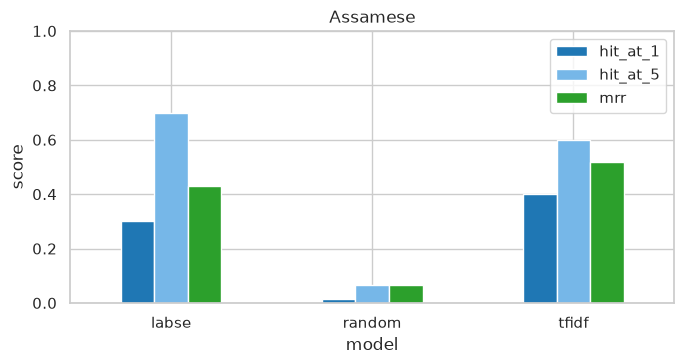

In [6]:
sub = summary.loc['Assamese']
fig, ax = plt.subplots(figsize=(7, 3.8))
sub[['hit_at_1', 'hit_at_5', 'mrr']].plot.bar(ax=ax, color=['#1f77b4', '#76b7e8', '#2ca02c'])
ax.set_ylim(0, 1); ax.set_ylabel('score'); ax.set_title('Assamese'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Figure 3: Assamese reverse retrieval. Hit@1, Hit@5 and MRR for the TF-IDF and LaBSE indexes against the random baseline.**

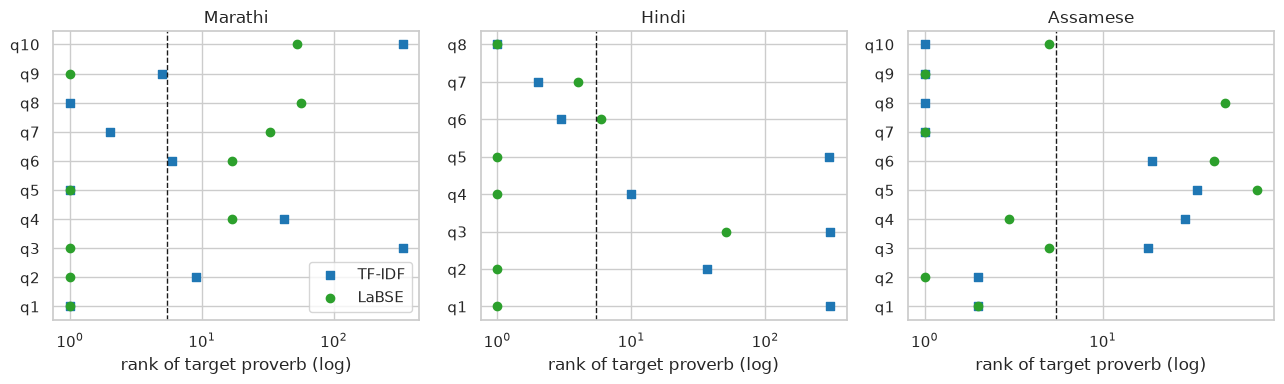

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
for ax, (l, L) in zip(axes, LANGS):
    sub = ranks[ranks.language == L].pivot(index='situation', columns='model', values='rank')
    y = np.arange(len(sub))
    ax.scatter(sub['tfidf'], y, marker='s', color='#1f77b4', label='TF-IDF')
    ax.scatter(sub['labse'], y, marker='o', color='#2ca02c', label='LaBSE')
    ax.axvline(5.5, color='k', ls='--', lw=1)
    ax.set_yticks(y); ax.set_yticklabels([f'q{i+1}' for i in y]); ax.set_xscale('log'); ax.set_xlabel('rank of target proverb (log)'); ax.set_title(L)
axes[0].legend(); plt.tight_layout(); plt.show()

**Figure 4: Rank of the target proverb for every situation query, per language and index. Points left of the dashed line are top-5 hits.**

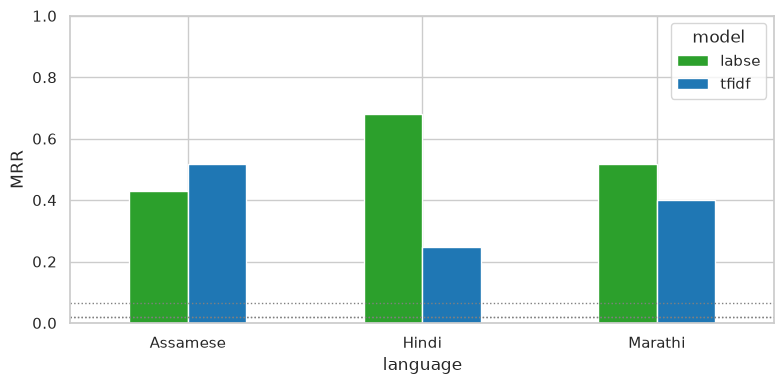

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
best = summary.reset_index()
best = best[best.model != 'random'].pivot(index='language', columns='model', values='mrr')
best.plot.bar(ax=ax, color=['#2ca02c', '#1f77b4']); ax.set_ylabel('MRR'); ax.set_ylim(0, 1); plt.xticks(rotation=0)
for l, L in LANGS:
    ax.axhline(summary.loc[(L, 'random'), 'mrr'], color='grey', ls=':', lw=1)
plt.tight_layout(); plt.show()

**Figure 5: Mean reciprocal rank by language and index; dotted grey lines are the random baselines.**

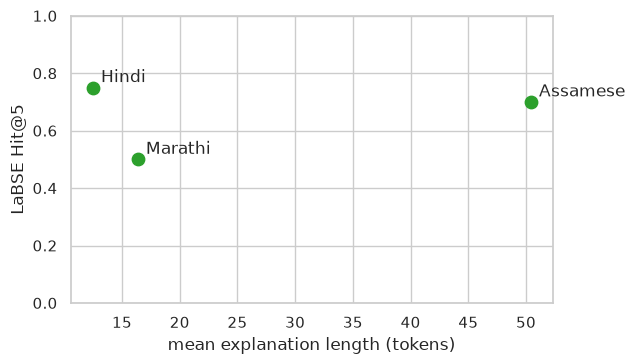

In [9]:
lengths = pd.Series({L: with_expl[l].commentary.str.split().str.len().mean() for l, L in LANGS})
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(lengths.values, [summary.loc[(L, 'labse'), 'hit_at_5'] for L in lengths.index], s=80, color='#2ca02c')
for L, x in lengths.items():
    ax.annotate(L, (x, summary.loc[(L, 'labse'), 'hit_at_5']), textcoords='offset points', xytext=(6, 4))
ax.set_xlabel('mean explanation length (tokens)'); ax.set_ylabel('LaBSE Hit@5'); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Figure 6: Hit@5 against the average length of the indexed explanations. Longer explanations give the index more to match on.**

## 4. The interface

`suggest()` is what a chatbot calls: it takes a situation and a language and returns the top proverbs with their literal translation and meaning.

In [10]:
def suggest(query, lang='hindi', k=3, model='labse'):
    ids, sims = rank_ids(lang, query, model)
    out = with_expl[lang].set_index('id').loc[ids[:k], ['proverb_translit', 'literal_en', 'commentary']].copy()
    out.insert(0, 'similarity', np.round(sims[:k], 3))
    return out

suggest('someone keeps complaining about a very small loss', lang='marathi')

,similarity,proverb_translit,literal_en,commentary
id,,,,
437,0.342,Jyaeyft tyScTll pari puraWto hari,Hari givet to men according to their tiaie.,"To the rich he givee much, to the poor little."
473,0.321,XJpata sula ghe khandyavara,"PkU up tie impaling-ttake, take it on yovr tho...",Some people bring about their own deBtructioD.
7,0.315,KliaDdiDiadhye pava rati,An ounce »hort in a cart-load.,Why trouble abont so trivial a matter?


In [11]:
json.dump(metrics, open('report/PanelB_16_CCA3_v2_reverse_retrieval_metrics.json', 'w'), indent=1)
print(json.dumps(metrics, indent=1)[:2000])

{
 "summary": {
  "Assamese/labse": {
   "hit_at_1": 0.3,
   "hit_at_5": 0.7,
   "mrr": 0.429
  },
  "Assamese/random": {
   "hit_at_1": 0.013,
   "hit_at_5": 0.067,
   "mrr": 0.065
  },
  "Assamese/tfidf": {
   "hit_at_1": 0.4,
   "hit_at_5": 0.6,
   "mrr": 0.517
  },
  "Hindi/labse": {
   "hit_at_1": 0.625,
   "hit_at_5": 0.75,
   "mrr": 0.68
  },
  "Hindi/random": {
   "hit_at_1": 0.003,
   "hit_at_5": 0.016,
   "mrr": 0.021
  },
  "Hindi/tfidf": {
   "hit_at_1": 0.125,
   "hit_at_5": 0.375,
   "mrr": 0.246
  },
  "Marathi/labse": {
   "hit_at_1": 0.5,
   "hit_at_5": 0.5,
   "mrr": 0.518
  },
  "Marathi/random": {
   "hit_at_1": 0.003,
   "hit_at_5": 0.015,
   "mrr": 0.019
  },
  "Marathi/tfidf": {
   "hit_at_1": 0.3,
   "hit_at_5": 0.5,
   "mrr": 0.401
  }
 },
 "n_queries": {
  "Marathi": 10,
  "Hindi": 8,
  "Assamese": 10
 }
}


## Summary

Across the three corpora the target proverb reaches the top five for most of the hand-written situations, against random baselines of a few percent. The semantic index wins on MRR for Marathi and Hindi; for Assamese the lexical index is slightly ahead because several situations share concrete words with the long Gurdon explanations. The `suggest()` function is the retrieval back end for the team chatbot.

**References**
- Feng, F., Yang, Y., Cer, D., Arivazhagan, N., & Wang, W. (2022). Language-agnostic BERT sentence embedding. *Proceedings of ACL 2022*, 878-891.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of EMNLP-IJCNLP 2019*, 3982-3992.